In [1]:
from dataloader import load_all_data
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'''\usepackage{libertine}\usepackage{fontawesome5}\usepackage{xcolor}'''
plt.rcParams['ps.usedistiller'] = 'xpdf'
import seaborn as sns
sns.set_theme(style='ticks')
from statannotations.Annotator import Annotator

In [2]:
interfaces = {
    'pointwise':        'UI1',
    'pairwise':         'UI2',
    'listwise-rating':  'UI3',
    'listwise-notie':   'UI4',
    'listwise-cantie':  'UI5',
    'listwise-ranking': 'UI6',
}

_, _, df_finishs, _ = load_all_data()
df_finishs['confidence_inv'] = 100 - df_finishs['confidence']
df_finishs['regret_inv'] = 100 - df_finishs['regret']
df_finishs['agg_satisfaction'] = df_finishs[['satisfaction', 'expectation', 'improvement', 'confidence_inv']].mean(axis=1)
df_finishs['agg_incompleteness'] = df_finishs[['incompletePreference', 'regret_inv']].mean(axis=1)
df_finishs.to_csv('processed/questionnaires.csv', index=False)

pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking
pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking


In [3]:
df_finishs.groupby("domain").count()

,confidence,confidenceTimestamp,expectation,expectationTimestamp,feedback,finishTimestamp,improvement,improvementTimestamp,incompletePreference,incompletePreferenceTimestamp,...,satisfactionTimestamp,sessionID,studyID,taskID,userID,interface,confidence_inv,regret_inv,agg_satisfaction,agg_incompleteness
domain,,,,,,,,,,,,,,,,,,,,,
image,540,540,540,540,540,540,540,540,540,540,...,540,540,540,540,540,540,540,540,540,540
text,540,540,540,540,540,540,540,540,540,540,...,540,540,540,540,540,540,540,540,540,540


In [4]:
import pingouin as pg
pg.cronbach_alpha(df_finishs[['satisfaction', 'expectation', 'improvement', 'confidence_inv']])

(0.7962064178061381, array([0.776, 0.815]))

In [5]:
pg.cronbach_alpha(df_finishs[['incompletePreference', 'regret_inv']])

(0.10254647349430135, array([-0.011,  0.204]))

In [6]:
df_finishs[['interface', 'taskID', 'agg_satisfaction', 'incompletePreference', 'regret']].groupby('interface').describe()

agg_satisfaction                                              \
                            count       mean        std  min      25%     50%   
interface                                                                       
listwise-cantie             180.0  61.825000  19.586827  0.0  53.0000  63.250   
listwise-notie              180.0  59.618056  17.987881  0.0  49.6875  60.500   
listwise-ranking            180.0  62.365278  21.058418  0.0  50.3750  64.875   
listwise-rating             180.0  58.284722  19.437081  0.0  49.2500  58.500   
pairwise                    180.0  63.755556  18.662317  0.0  53.5000  64.000   
pointwise                   180.0  57.025000  20.323056  0.0  44.2500  59.750   

                                  incompletePreference             ...         \
                      75%     max                count       mean  ...    75%   
interface                                                          ...          
listwise-cantie   74.2500  100.00                180.0  35.955556  ...  50.00   
listwise-notie    71.6250   97.00                180.0  43.405556  ...  59.00   
listwise-ranking  77.0625  100.00                180.0  30.427778  ...  50.00   
listwise-rating   73.2500   95.75                180.0  39.038889  ...  55.50   
pairwise          76.0625  100.00                180.0  41.133333  ...  56.25   
pointwise         70.2500  100.00                180.0  31.588889  ...  50.00   

                        regret                                           \
                    max  count       mean        std   min    25%   50%   
interface                                                                 
listwise-cantie   100.0  180.0  75.022222  19.977349   0.0  63.75  75.5   
listwise-notie    100.0  180.0  75.083333  21.526877   2.0  61.75  78.0   
listwise-ranking  100.0  180.0  79.005556  18.141128  23.0  67.00  82.0   
listwise-rating    99.0  180.0  76.233333  18.289754  21.0  64.75  78.0   
pairwise          100.0  180.0  72.477778  18.998223  22.0  61.00  72.5   
pointwise         100.0  180.0  75.372222  20.958600   5.0  62.00  78.0   

                                
                    75%    max  
interface                       
listwise-cantie   90.00  100.0  
listwise-notie    95.00  100.0  
listwise-ranking  95.25  100.0  
listwise-rating   91.00  100.0  
pairwise          88.00  100.0  
pointwise         93.00  100.0  

[6 rows x 24 columns]

In [7]:
questions = ['agg_satisfaction', 'incompletePreference', 'regret']
fontsize = 11
colors = ['#c26f6d', '#d9a6a4', '#f2dfdd', '#e4e5eb', '#aab8d0', '#6e90bf']

df_text = df_finishs[df_finishs.domain == 'text'].groupby(['userID', 'interface']).mean().reset_index()
df_text

,userID,interface,confidence,confidenceTimestamp,expectation,expectationTimestamp,finishTimestamp,improvement,improvementTimestamp,incompletePreference,incompletePreferenceTimestamp,regret,regretTimestamp,satisfaction,satisfactionTimestamp,confidence_inv,regret_inv,agg_satisfaction,agg_incompleteness
0,P129,listwise-notie,82.000000,1.662211e+12,42.000000,1.662211e+12,1.662211e+12,52.333333,1.662211e+12,56.666667,1.662211e+12,53.333333,1.662211e+12,41.333333,1.662211e+12,18.000000,46.666667,38.416667,51.666667
1,P004,pointwise,52.666667,5.540975e+11,43.000000,1.108195e+12,1.662293e+12,39.666667,1.108195e+12,39.666667,5.540975e+11,57.000000,1.108195e+12,48.666667,1.108195e+12,47.333333,43.000000,44.666667,41.333333
2,P066,pairwise,91.000000,1.662192e+12,93.666667,1.662192e+12,1.662192e+12,87.000000,1.662192e+12,48.666667,1.108128e+12,99.666667,1.662192e+12,99.666667,1.662192e+12,9.000000,0.333333,72.333333,24.500000
3,P342,listwise-ranking,98.000000,1.661928e+12,90.000000,1.661928e+12,1.661928e+12,94.000000,1.661928e+12,33.666667,1.661928e+12,90.666667,1.661928e+12,94.666667,1.661928e+12,2.000000,9.333333,70.166667,21.500000
4,P057,listwise-cantie,49.333333,1.662221e+12,63.666667,1.662221e+12,1.662221e+12,57.000000,1.108148e+12,32.333333,1.108148e+12,71.000000,1.662221e+12,77.333333,1.662221e+12,50.666667,29.000000,62.166667,30.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,P175,listwise-rating,56.000000,1.661928e+12,81.333333,1.661928e+12,1.661928e+12,87.333333,1.661928e+12,53.333333,1.661928e+12,77.000000,1.661928e+12,87.000000,1.661928e+12,44.000000,23.000000,74.916667,38.166667
176,P070,pointwise,78.000000,1.662543e+12,35.000000,1.662543e+12,1.662543e+12,35.000000,1.662543e+12,5.333333,1.662543e+12,46.000000,1.662543e+12,40.333333,1.662543e+12,22.000000,54.000000,33.083333,29.666667
177,P338,listwise-ranking,6.333333,1.661932e+12,93.000000,1.661932e+12,1.661932e+12,66.666667,5.539773e+11,39.000000,5.539773e+11,83.333333,1.107955e+12,98.000000,1.661932e+12,93.666667,16.666667,87.833333,27.833333
178,P225,listwise-rating,89.333333,1.661928e+12,45.666667,1.661928e+12,1.661928e+12,40.000000,1.661928e+12,0.000000,1.661928e+12,88.666667,1.661928e+12,46.666667,1.661928e+12,10.666667,11.333333,35.750000,5.666667


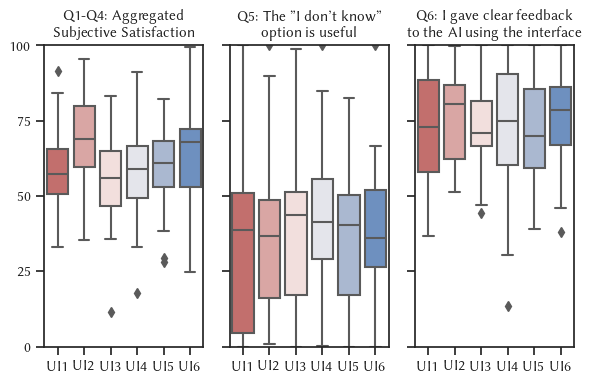

In [8]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(6, 4))

for i, question in enumerate(questions):
    sns.boxplot(ax=axes[i], data=df_text, x='interface', order=interfaces, y=question, palette=colors, saturation=1)
    axes[i].set_ylabel('')
    axes[i].set_xlabel('')
    axes[i].set_xticklabels(list(interfaces.values()), fontsize=fontsize)
    axes[i].set_ylim(0, 100)
    axes[i].set_yticks([0, 25, 50, 75, 100])
    axes[i].set_yticklabels(['0', '25', '50', '75', '100'], fontsize=fontsize)
    if i != 0:
        axes[i].set_yticklabels([])

# annot = Annotator(axes[0], [
#     ('pointwise', 'pairwise'),               # H1
#     # ('pointwise', 'listwise-rating'),        # H2a
#     # ('pairwise',  'listwise-cantie'),        # H2b
#     # ('listwise-rating', 'listwise-cantie'),  # H3a
#     # ('listwise-notie', 'listwise-cantie'),   # H3b
#     # ('listwise-ranking', 'pairwise'),        # H4a
#     ('listwise-ranking', 'listwise-rating'), # H4b
#     ('listwise-ranking', 'listwise-notie'),  # H4c
#     # ('listwise-ranking', 'listwise-cantie'), # H4d
# ], data=df_finishs, x='interface', y='agg_satisfaction', order=interfaces, show_non_significant=True)
# annot.set_custom_annotations(['H1: ***', 'H4b: *', 'H4c: *'])
# annot.annotate()

# annot = Annotator(axes[1], [
#     # ('pointwise', 'pairwise'),               # H1
#     # ('pointwise', 'listwise-rating'),        # H2a
#     # ('pairwise',  'listwise-cantie'),        # H2b
#     # ('listwise-rating', 'listwise-cantie'),  # H3a
#     # ('listwise-notie', 'listwise-cantie'),   # H3b
#     ('listwise-ranking', 'pairwise'),        # H4a
#     ('listwise-ranking', 'listwise-rating'), # H4b
#     ('listwise-ranking', 'listwise-notie'),  # H4c
#     ('listwise-ranking', 'listwise-cantie'), # H4d
# ], data=df_finishs, x='interface', y='incompletePreference', order=interfaces, show_non_significant=True)
# annot.set_custom_annotations(['H4a: ***', 'H4b: ***', 'H4c: ***', 'H4d: ***'])
# annot.annotate()

# annot = Annotator(axes[2], [
#     ('pointwise', 'pairwise'),               # H1
#     # ('pointwise', 'listwise-rating'),        # H2a
#     # ('pairwise',  'listwise-cantie'),        # H2b
#     # ('listwise-rating', 'listwise-cantie'),  # H3a
#     # ('listwise-notie', 'listwise-cantie'),   # H3b
#     ('listwise-ranking', 'pairwise'),        # H4a
#     # ('listwise-ranking', 'listwise-rating'), # H4b
#     # ('listwise-ranking', 'listwise-notie'),  # H4c
#     ('listwise-ranking', 'listwise-cantie'), # H4d
# ], data=df_finishs, x='interface', y='incompletePreference', order=interfaces, show_non_significant=True)
# annot.set_custom_annotations(['H1: *', 'H4a: ***', 'H4d: *'])
# annot.annotate()

axes[0].set_title('Q1-Q4: Aggregated\nSubjective Satisfaction', fontsize=fontsize)
axes[1].set_title('Q5: The "I don\'t know"\noption is useful', fontsize=fontsize)
axes[2].set_title('Q6: I gave clear feedback\nto the AI using the interface', fontsize=fontsize)
plt.tight_layout()
plt.savefig('figures/questionnaires_text.pdf', bbox_inches='tight', pad_inches=0)

In [9]:
questions = ['agg_satisfaction', 'incompletePreference', 'regret']
fontsize = 11
colors = ['#c26f6d', '#d9a6a4', '#f2dfdd', '#e4e5eb', '#aab8d0', '#6e90bf']
df_image = df_finishs[df_finishs.domain == 'image'].groupby(['userID', 'interface']).mean().reset_index()
df_image

,userID,interface,confidence,confidenceTimestamp,expectation,expectationTimestamp,finishTimestamp,improvement,improvementTimestamp,incompletePreference,incompletePreferenceTimestamp,regret,regretTimestamp,satisfaction,satisfactionTimestamp,confidence_inv,regret_inv,agg_satisfaction,agg_incompleteness
0,P042,listwise-rating,100.000000,1.670113e+12,37.333333,1.670113e+12,1.670113e+12,45.000000,1.113409e+12,50.000000,1.670113e+12,66.000000,1.670113e+12,42.000000,1.670113e+12,0.000000,34.000000,31.083333,42.000000
1,P248,pairwise,74.333333,1.670357e+12,68.333333,1.670357e+12,1.670357e+12,67.333333,1.670357e+12,40.666667,1.670357e+12,69.000000,1.670357e+12,55.333333,1.670357e+12,25.666667,31.000000,54.166667,35.833333
2,P192,listwise-cantie,78.333333,1.670158e+12,75.000000,1.670158e+12,1.670158e+12,74.666667,1.670158e+12,44.000000,1.670158e+12,72.333333,1.670158e+12,78.000000,1.670158e+12,21.666667,27.666667,62.333333,35.833333
3,P273,pointwise,80.666667,1.670283e+12,76.333333,1.670283e+12,1.670283e+12,64.000000,1.670283e+12,0.666667,1.670283e+12,89.333333,1.670283e+12,78.666667,1.670283e+12,19.333333,10.666667,59.583333,5.666667
4,P133,listwise-rating,68.333333,1.670120e+12,63.666667,1.670120e+12,1.670120e+12,80.000000,1.670120e+12,7.666667,1.670120e+12,100.000000,1.670120e+12,64.333333,1.670120e+12,31.666667,0.000000,59.916667,3.833333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,P294,pairwise,39.666667,1.670188e+12,83.333333,1.670188e+12,1.670188e+12,81.333333,1.670188e+12,45.666667,1.670188e+12,88.666667,1.670188e+12,84.000000,1.670188e+12,60.333333,11.333333,77.250000,28.500000
176,P121,listwise-ranking,59.000000,1.670183e+12,89.666667,1.670183e+12,1.670183e+12,100.000000,1.670183e+12,38.333333,1.113455e+12,95.666667,1.670183e+12,96.000000,1.670183e+12,41.000000,4.333333,81.666667,21.333333
177,P050,listwise-ranking,26.333333,1.670178e+12,53.333333,1.670178e+12,1.670178e+12,62.333333,1.670178e+12,7.000000,1.670178e+12,45.000000,1.670178e+12,51.333333,1.670178e+12,73.666667,55.000000,60.166667,31.000000
178,P160,listwise-notie,79.333333,1.670172e+12,45.333333,1.670172e+12,1.670172e+12,71.333333,1.670172e+12,25.333333,1.113448e+12,43.333333,1.670172e+12,39.000000,1.670172e+12,20.666667,56.666667,44.083333,41.000000


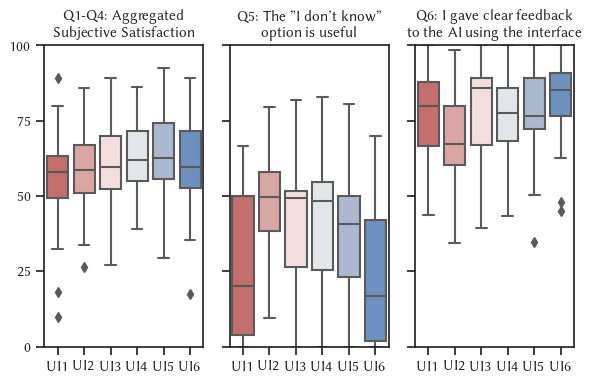

In [10]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(6, 4))
for i, question in enumerate(questions):
    sns.boxplot(ax=axes[i], data=df_image, x='interface', order=interfaces, y=question, palette=colors, saturation=1)
    axes[i].set_ylabel('')
    axes[i].set_xlabel('')
    axes[i].set_xticklabels(list(interfaces.values()), fontsize=fontsize)
    axes[i].set_ylim(0, 100)
    axes[i].set_yticks([0, 25, 50, 75, 100])
    axes[i].set_yticklabels(['0', '25', '50', '75', '100'], fontsize=fontsize)
    if i != 0:
        axes[i].set_yticklabels([])

# annot = Annotator(axes[0], [
#     ('pointwise', 'pairwise'),               # H1
#     # ('pointwise', 'listwise-rating'),        # H2a
#     # ('pairwise',  'listwise-cantie'),        # H2b
#     # ('listwise-rating', 'listwise-cantie'),  # H3a
#     # ('listwise-notie', 'listwise-cantie'),   # H3b
#     # ('listwise-ranking', 'pairwise'),        # H4a
#     ('listwise-ranking', 'listwise-rating'), # H4b
#     ('listwise-ranking', 'listwise-notie'),  # H4c
#     # ('listwise-ranking', 'listwise-cantie'), # H4d
# ], data=df_finishs, x='interface', y='agg_satisfaction', order=interfaces, show_non_significant=True)
# annot.set_custom_annotations(['H1: ***', 'H4b: *', 'H4c: *'])
# annot.annotate()

# annot = Annotator(axes[1], [
#     # ('pointwise', 'pairwise'),               # H1
#     # ('pointwise', 'listwise-rating'),        # H2a
#     # ('pairwise',  'listwise-cantie'),        # H2b
#     # ('listwise-rating', 'listwise-cantie'),  # H3a
#     # ('listwise-notie', 'listwise-cantie'),   # H3b
#     ('listwise-ranking', 'pairwise'),        # H4a
#     ('listwise-ranking', 'listwise-rating'), # H4b
#     ('listwise-ranking', 'listwise-notie'),  # H4c
#     ('listwise-ranking', 'listwise-cantie'), # H4d
# ], data=df_finishs, x='interface', y='incompletePreference', order=interfaces, show_non_significant=True)
# annot.set_custom_annotations(['H4a: ***', 'H4b: ***', 'H4c: ***', 'H4d: ***'])
# annot.annotate()

# annot = Annotator(axes[2], [
#     ('pointwise', 'pairwise'),               # H1
#     # ('pointwise', 'listwise-rating'),        # H2a
#     # ('pairwise',  'listwise-cantie'),        # H2b
#     # ('listwise-rating', 'listwise-cantie'),  # H3a
#     # ('listwise-notie', 'listwise-cantie'),   # H3b
#     ('listwise-ranking', 'pairwise'),        # H4a
#     # ('listwise-ranking', 'listwise-rating'), # H4b
#     # ('listwise-ranking', 'listwise-notie'),  # H4c
#     ('listwise-ranking', 'listwise-cantie'), # H4d
# ], data=df_finishs, x='interface', y='incompletePreference', order=interfaces, show_non_significant=True)
# annot.set_custom_annotations(['H1: *', 'H4a: ***', 'H4d: *'])
# annot.annotate()

axes[0].set_title('Q1-Q4: Aggregated\nSubjective Satisfaction', fontsize=fontsize)
axes[1].set_title('Q5: The "I don\'t know"\noption is useful', fontsize=fontsize)
axes[2].set_title('Q6: I gave clear feedback\nto the AI using the interface', fontsize=fontsize)
plt.tight_layout()
plt.savefig('figures/questionnaires_image.pdf', bbox_inches='tight', pad_inches=0)

In [11]:
from stats import pairwise_test

pairs = [
        ('pointwise', 'pairwise'),               # H1
        ('pointwise', 'listwise-rating'),        # H2a
        ('pairwise',  'listwise-cantie'),        # H2b
        ('listwise-rating', 'listwise-cantie'),  # H3a
        ('listwise-notie', 'listwise-cantie'),   # H3b
        ('listwise-ranking', 'pairwise'),        # H4a
        ('listwise-ranking', 'listwise-rating'), # H4b
        ('listwise-ranking', 'listwise-notie'),  # H4c
        ('listwise-ranking', 'listwise-cantie'), # H4d
]

pairwise_test(df_finishs, 'interface', 'agg_satisfaction', pairs)[['test_name', 'level1', 'level2', 'sig', 'p', 'W']]

,test_name,level1,level2,sig,p,W
0,Mann-Whitney U test,pointwise,pairwise,***,0.0005538407690673858,12979.5
1,Mann-Whitney U test,pointwise,listwise-rating,n.s.,0.6687887310502912,15769.5
2,Mann-Whitney U test,pairwise,listwise-cantie,n.s.,0.19129319318827537,17062.5
3,Mann-Whitney U test,listwise-rating,listwise-cantie,*,0.02092735713227061,14190.5
4,Mann-Whitney U test,listwise-notie,listwise-cantie,n.s.,0.06764552036772964,14725.0
5,Mann-Whitney U test,listwise-ranking,pairwise,n.s.,0.6591828713320613,15795.5
6,Mann-Whitney U test,listwise-ranking,listwise-rating,*,0.011063258976700806,18459.5
7,Mann-Whitney U test,listwise-ranking,listwise-notie,*,0.03078603766718488,18046.0
8,Mann-Whitney U test,listwise-ranking,listwise-cantie,n.s.,0.31755243627727125,16669.0


In [12]:
pairwise_test(df_finishs, 'interface', 'incompletePreference', pairs)[['test_name', 'level1', 'level2', 'sig', 'p', 'W']]

,test_name,level1,level2,sig,p,W
0,Mann-Whitney U test,pointwise,pairwise,***,0.0003351317907844995,12860.5
1,Mann-Whitney U test,pointwise,listwise-rating,**,0.0033387428822562945,13541.0
2,Mann-Whitney U test,pairwise,listwise-cantie,*,0.041500285297736084,17905.5
3,Mann-Whitney U test,listwise-rating,listwise-cantie,n.s.,0.12855085190078652,17314.0
4,Mann-Whitney U test,listwise-notie,listwise-cantie,**,0.009050182585235586,18524.0
5,Mann-Whitney U test,listwise-ranking,pairwise,***,6.530466621068461e-05,12439.0
6,Mann-Whitney U test,listwise-ranking,listwise-rating,***,0.0009128361222404347,13138.5
7,Mann-Whitney U test,listwise-ranking,listwise-notie,***,6.0845075360047995e-06,11901.5
8,Mann-Whitney U test,listwise-ranking,listwise-cantie,*,0.02440408275140276,14268.5


In [13]:
pairwise_test(df_finishs, 'interface', 'regret', pairs)[['test_name', 'level1', 'level2', 'sig', 'p', 'W']]

,test_name,level1,level2,sig,p,W
0,Mann-Whitney U test,pointwise,pairwise,*,0.0363907801391194,17969.0
1,Mann-Whitney U test,pointwise,listwise-rating,n.s.,0.9579368748626358,16252.5
2,Mann-Whitney U test,pairwise,listwise-cantie,n.s.,0.08029990791285446,14816.5
3,Mann-Whitney U test,listwise-rating,listwise-cantie,n.s.,0.3614882098982787,16550.0
4,Mann-Whitney U test,listwise-notie,listwise-cantie,n.s.,0.421264830128148,16396.0
5,Mann-Whitney U test,listwise-ranking,pairwise,***,0.0003474150533909046,19541.0
6,Mann-Whitney U test,listwise-ranking,listwise-rating,*,0.04610846581061945,17859.5
7,Mann-Whitney U test,listwise-ranking,listwise-notie,n.s.,0.05379470403265769,17782.0
8,Mann-Whitney U test,listwise-ranking,listwise-cantie,*,0.026687679201118288,18100.5


## Qualitative

In [14]:
userIDs = df_finishs.userID.unique()
for idx, userID in enumerate(userIDs):
    df_finishs[df_finishs.userID == userID].iloc
    df_finishs.loc[df_finishs['userID'] == userID, 'pid'] = f'P{idx+1}'
df_finishs[['pid', 'domain', 'interface', 'taskID', 'feedback']]

,pid,domain,interface,taskID,feedback
0,P1,text,pointwise,3,The same summary was given out several times d...
1,P1,text,pointwise,2,The AI gave already an initial good summary. T...
2,P1,text,pointwise,1,"Good summaries. However, connectives are missi..."
3,P2,text,pointwise,1,The AI seems pretty unresponsive once you show...
4,P2,text,pointwise,2,"This one was great from the first try, so ther..."
...,...,...,...,...,...
1075,P359,image,listwise-ranking,3,
1076,P359,image,listwise-ranking,2,
1077,P360,image,listwise-ranking,3,
1078,P360,image,listwise-ranking,1,


In [15]:
df_feedback = df_finishs[['pid', 'domain', 'interface', 'taskID', 'feedback']]
df_feedback['sentiment'] = 0.5
# drop rows that feedback is empty
df_feedback.to_csv('processed/feedback.csv', index=False)
df_feedback.feedback

0       The same summary was given out several times d...
1       The AI gave already an initial good summary. T...
2       Good summaries. However, connectives are missi...
3       The AI seems pretty unresponsive once you show...
4       This one was great from the first try, so ther...
                              ...                        
1075                                                     
1076                                                     
1077                                                     
1078                                                     
1079                                                     
Name: feedback, Length: 1080, dtype: object

In [16]:
df_feedback[df_feedback.feedback != ''].count()

pid          695
domain       695
interface    695
taskID       695
feedback     695
sentiment    695
dtype: int64

In [17]:
df_feedback_desc = df_feedback[df_feedback.feedback != ''].groupby(['domain', 'interface']).describe().reset_index()

df_feedback_desc = pd.DataFrame({
    'domain': df_feedback_desc.domain,
    'interface': df_feedback_desc.interface,
    'count': df_feedback_desc['sentiment', 'count'],
})
df_feedback_desc['percent'] = df_feedback_desc['count'] * 100 / df_feedback_desc['count'].sum() 
df_feedback_desc

,domain,interface,count,percent
0,image,listwise-cantie,44.0,6.330935
1,image,listwise-notie,51.0,7.338129
2,image,listwise-ranking,51.0,7.338129
3,image,listwise-rating,53.0,7.625899
4,image,pairwise,57.0,8.201439
5,image,pointwise,70.0,10.071942
6,text,listwise-cantie,56.0,8.057554
7,text,listwise-notie,56.0,8.057554
8,text,listwise-ranking,51.0,7.338129
9,text,listwise-rating,69.0,9.928058


In [18]:
import openai

def analyze_sentiment(df, redo=False):
    if not redo:
        return pd.read_csv('processed/feedback_sentiment.csv')

    df_feedback = df.copy()
    for idx, row in df_feedback.iterrows():
        feedback = row.feedback
        if feedback == '':
            continue

        retry = 0
        while True:
            try:
                # Call OpenAI's chatgpt-3.5-turbo model to generate a response
                message_history = [{
                    "role": "user",
                    "content": f"Generate a sentiment score for the following message any following messages. Please use float values from 0 to 1"
                }, {
                    "role": "assistant",
                    "content": f"Okay I will respond with only a value from 0 to 1. 0 is the most negative and 1 is the most positive.",
                }]

                message_history.append({"role": "user", "content": f"{feedback}"})
                completion = openai.ChatCompletion.create(
                    model="gpt-3.5-turbo",
                    messages=message_history
                )
                def numberFromString(s):
                    temp = float(''.join(ele for ele in s if ele.isdigit() or ele == '.'))
                    #if temp is less than -1 or greater than 1 then it is not a valid score and return 0
                    if temp < -1 or temp > 1:
                        return 0
                    return temp

                print(completion.choices[0].message.content)
                #parse value from response
                tempScore = numberFromString(completion.choices[0].message.content)
                break
            except:
                retry += 1
                if retry > 5:
                    tempScore = 0.5
                    break

                print("error on feedback: ", idx, feedback)
                continue
        print(f"our tempscore {tempScore} from content {completion.choices[0].message.content}")
        df_feedback.at[idx, 'sentiment'] = tempScore
        df_feedback.to_csv('processed/feedback_sentiment.csv', index=False)
    return df_feedback

df_sentiment = analyze_sentiment(df_feedback, redo=False)
df_sentiment

,userID,domain,interface,feedback,sentiment
0,P330,text,pointwise,The same summary was given out several times d...,0.20
1,P330,text,pointwise,The AI gave already an initial good summary. T...,0.80
2,P330,text,pointwise,"Good summaries. However, connectives are missi...",0.40
3,P095,text,pointwise,The AI seems pretty unresponsive once you show...,0.25
4,P095,text,pointwise,"This one was great from the first try, so ther...",0.90
...,...,...,...,...,...
1074,P071,image,listwise-ranking,NaN,0.50
1075,P071,image,listwise-ranking,NaN,0.50
1076,P149,image,listwise-ranking,NaN,0.50
1077,P149,image,listwise-ranking,NaN,0.50


In [19]:
df_sentiment_text = df_sentiment[df_sentiment.domain == 'text'].groupby(['userID', 'domain', 'interface']).mean().reset_index()
df_sentiment_image = df_sentiment[df_sentiment.domain == 'image'].groupby(['userID', 'domain', 'interface']).mean().reset_index()

In [20]:
df_sentiment_text

,userID,domain,interface,sentiment
0,P129,text,listwise-notie,0.266667
1,P004,text,pointwise,0.566667
2,P066,text,pairwise,0.600000
3,P342,text,listwise-ranking,0.633333
4,P057,text,listwise-cantie,0.500000
...,...,...,...,...
175,P175,text,listwise-rating,0.566667
176,P070,text,pointwise,0.200000
177,P338,text,listwise-ranking,0.600000
178,P225,text,listwise-rating,0.266667


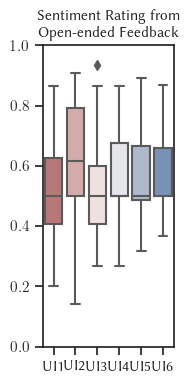

In [21]:
fig, axes = plt.subplots(1, 1, figsize=(2, 4))
sns.boxplot(ax=axes, data=df_sentiment_text, x='interface', y='sentiment', order=interfaces, palette=colors)
axes.set_xticklabels(list(interfaces.values()))
axes.set_ylim(0, 1)
axes.set_title('Sentiment Rating from\nOpen-ended Feedback', fontsize=fontsize)
axes.set_ylabel('', fontsize=fontsize)
axes.set_xlabel('', fontsize=fontsize)
axes.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1])

# annot = Annotator(axes, [
#     ('pointwise', 'pairwise'),               # H1
#     ('pointwise', 'listwise-rating'),        # H2a
#     ('pairwise',  'listwise-cantie'),        # H2b
#     # ('listwise-rating', 'listwise-cantie'),  # H3a
#     # ('listwise-notie', 'listwise-cantie'),   # H3b
#     # ('listwise-ranking', 'pairwise'),        # H4a
#     ('listwise-ranking', 'listwise-rating'), # H4b
#     ('listwise-ranking', 'listwise-notie'),  # H4c
#     ('listwise-ranking', 'listwise-cantie'), # H4d
# ], data=df_finishs, x='interface', y='incompletePreference', order=interfaces, show_non_significant=True)
# annot.set_custom_annotations(['H1: ***', 'H2a: **', 'H2b: *', 'H4b: *', 'H4c: *', 'H4d: *'])
# annot.annotate()

plt.tight_layout()
plt.savefig('figures/sentiment_text.pdf', bbox_inches='tight', pad_inches=0)

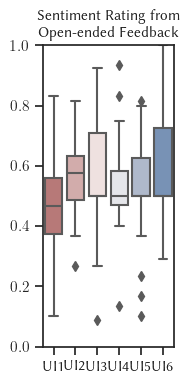

In [22]:
fig, axes = plt.subplots(1, 1, figsize=(2, 4))
sns.boxplot(ax=axes, data=df_sentiment_image, x='interface', y='sentiment', order=interfaces, palette=colors)
axes.set_xticklabels(list(interfaces.values()))
axes.set_ylim(0, 1)
axes.set_title('Sentiment Rating from\nOpen-ended Feedback', fontsize=fontsize)
axes.set_ylabel('', fontsize=fontsize)
axes.set_xlabel('', fontsize=fontsize)
axes.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1])

# annot = Annotator(axes, [
#     ('pointwise', 'pairwise'),               # H1
#     ('pointwise', 'listwise-rating'),        # H2a
#     ('pairwise',  'listwise-cantie'),        # H2b
#     # ('listwise-rating', 'listwise-cantie'),  # H3a
#     # ('listwise-notie', 'listwise-cantie'),   # H3b
#     # ('listwise-ranking', 'pairwise'),        # H4a
#     ('listwise-ranking', 'listwise-rating'), # H4b
#     ('listwise-ranking', 'listwise-notie'),  # H4c
#     ('listwise-ranking', 'listwise-cantie'), # H4d
# ], data=df_finishs, x='interface', y='incompletePreference', order=interfaces, show_non_significant=True)
# annot.set_custom_annotations(['H1: ***', 'H2a: **', 'H2b: *', 'H4b: *', 'H4c: *', 'H4d: *'])
# annot.annotate()

plt.tight_layout()
plt.savefig('figures/sentiment_image.pdf', bbox_inches='tight', pad_inches=0)

In [23]:
pairwise_test(df_sentiment.dropna(), 'interface', 'sentiment', pairs)[['test_name', 'level1', 'level2', 'sig', 'p', 'W']]

,test_name,level1,level2,sig,p,W
0,Mann-Whitney U test,pointwise,pairwise,***,1.0276845385212396e-05,6043.0
1,Mann-Whitney U test,pointwise,listwise-rating,**,0.007904443036359716,7115.5
2,Mann-Whitney U test,pairwise,listwise-cantie,*,0.04340102530883591,6909.5
3,Mann-Whitney U test,listwise-rating,listwise-cantie,n.s.,0.9991506848471587,6051.0
4,Mann-Whitney U test,listwise-notie,listwise-cantie,n.s.,0.4729149798971644,5320.5
5,Mann-Whitney U test,listwise-ranking,pairwise,n.s.,0.8838958501961375,6292.5
6,Mann-Whitney U test,listwise-ranking,listwise-rating,*,0.035266269880802885,7033.5
7,Mann-Whitney U test,listwise-ranking,listwise-notie,*,0.033813985404342134,6249.5
8,Mann-Whitney U test,listwise-ranking,listwise-cantie,*,0.04383118868813647,5804.5


In [24]:
df_sentiment.dropna().groupby(['domain', 'interface']).describe().reset_index()

domain         interface sentiment                                          \
                                count      mean       std     min    25%  50%   
0   image   listwise-cantie      44.0  0.560227  0.282139  0.0000  0.400  0.6   
1   image    listwise-notie      51.0  0.563137  0.265823  0.0000  0.350  0.5   
2   image  listwise-ranking      51.0  0.674902  0.264056  0.1000  0.500  0.8   
3   image   listwise-rating      53.0  0.624528  0.281102  0.0500  0.500  0.7   
4   image          pairwise      57.0  0.597368  0.257637  0.0000  0.450  0.7   
5   image         pointwise      70.0  0.467679  0.259794  0.0500  0.225  0.5   
6    text   listwise-cantie      56.0  0.594615  0.269042  0.1000  0.400  0.6   
7    text    listwise-notie      56.0  0.589509  0.271870  0.0625  0.400  0.5   
8    text  listwise-ranking      51.0  0.625686  0.237422  0.1000  0.400  0.7   
9    text   listwise-rating      68.0  0.542647  0.269503  0.1000  0.300  0.5   
10   text          pairwise      65.0  0.684231  0.259153  0.0500  0.500  0.8   
11   text         pointwise      72.0  0.528611  0.283903  0.0500  0.300  0.5   

                
    75%    max  
0   0.8  1.000  
1   0.8  0.950  
2   0.9  1.000  
3   0.9  0.975  
4   0.8  1.000  
5   0.7  1.000  
6   0.9  1.000  
7   0.9  1.000  
8   0.8  1.000  
9   0.8  0.950  
10  0.9  1.000  
11  0.8  0.960